## 6. RAG

### What is RAG?

Every company has documents the LLM has never seen: policies, price lists, FAQs. Ask about them, and the LLM guesses.

In [ ]:
# STEP 0 (run once): install the SDKs
# WHY (tech): Installs each provider's Python SDK, which handles HTTP requests, authentication and response parsing.
# ELI5: Download a translator app for each AI company.
!pip install -q -U google-genai openai anthropic
# If you later get an ImportError: Runtime -> Restart session, then run the cells again (skip this one).

In [ ]:
from google import genai
from google.genai import types
from google.colab import userdata
gemini = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
MODEL = "gemini-3.8-flash"
test = gemini.models.generate_content(model=MODEL, contents="Say OK")
print("✅ Gemini connected:", test.text)

from openai import OpenAI
from google.colab import userdata
openai_client = OpenAI(api_key=userdata.get("OPENAI_API_KEY"))
MODEL = "gpt-6.1-sol"
test = openai_client.chat.completions.create(model=MODEL, messages=[{"role": "user", "content": "Say OK"}])
print("✅ OpenAI connected:", test.choices[0].message.content)

import anthropic
from google.colab import userdata
claude = anthropic.Anthropic(api_key=userdata.get("ANTHROPIC_API_KEY"))
MODEL = "claude-sonnet-5-5"
test = claude.messages.create(model=MODEL, max_tokens=20, messages=[{"role": "user", "content": "Say OK"}])
print("✅ Claude connected:", test.content[-1].text)

from openai import OpenAI
from google.colab import userdata
groq = OpenAI(api_key=userdata.get("GROQ_API_KEY"), base_url="https://api.groq.com/openai/v1")
MODEL = "openai/gpt-oss-120b"
test = groq.chat.completions.create(model=MODEL, messages=[{"role": "user", "content": "Say OK"}])
print("✅ Groq connected:", test.choices[0].message.content)

✅ Gemini connected: OK
✅ OpenAI connected: OK
✅ Claude connected: OK
✅ Groq connected: OK


In [ ]:
response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    contents="I joined SkyFit Gym 10 days ago and want to cancel. Can I get a refund?",
)

print(response.text)

A generic answer, not SkyFit's actual rule. For a real customer, that's a problem.

**RAG (Retrieval Augmented Generation)** fixes this: first **find** the right part of your documents, then give **only that part** to the LLM to answer from. Like an open-book exam.

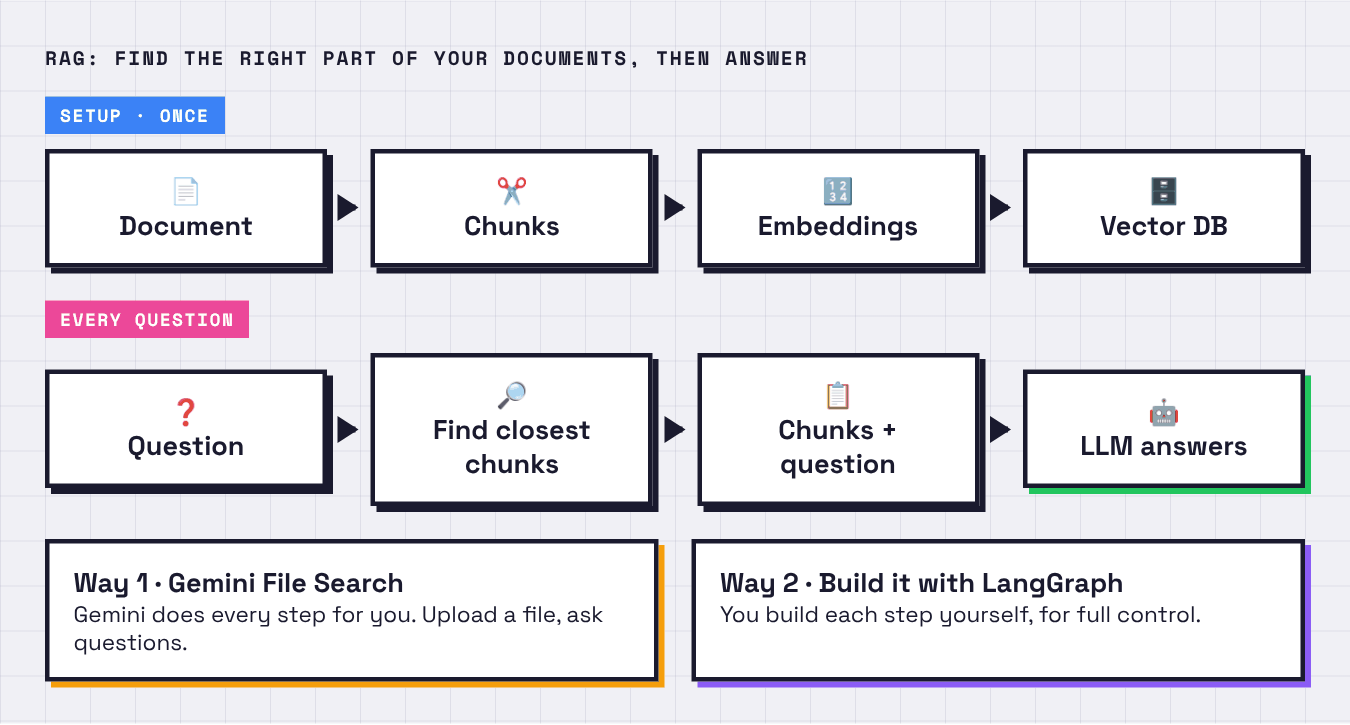

We'll do it in 2 ways:

1. **Gemini File Search:** Gemini does all the steps for you
2. **LangGraph:** you build each step yourself, for full control


### Upload the handbook

Upload `skyfit_handbook.md` (shared with this notebook): SkyFit Gym's plans, prices, refunds, freezes and rules. We use this one file in both ways.

In [3]:
from google.colab import files

uploaded = files.upload()
file_name = list(uploaded.keys())[0]

KeyboardInterrupt: 

6.1 Way 1: Gemini File Search
File Search is a built-in Gemini tool. You give it your files, and it takes care of chunking, embeddings and search. You just ask questions.

Step 1: create a store: a folder where Gemini keeps your documents, ready to be searched.

In [ ]:
store = gemini.file_search_stores.create(config={"display_name": "SkyFit_Gym_Membership_Policy"})

Step 2: upload the file. Gemini chunks it and creates embeddings. Takes a few seconds.

In [ ]:
import time

# The SDK's upload_to_file_search_store takes care of reading your local file,
# uploading it, and registering it to your vector database store in one step.
print("Uploading and indexing local file in the File Search Store...")
upload = gemini.file_search_stores.upload_to_file_search_store(
    file=file_name,
    file_search_store_name=store.name,
)

while not upload.done:
    print("Waiting for indexing in vector database...")
    time.sleep(3)
    upload = gemini.operations.get(upload)

print("File is successfully uploaded and indexed in your vector database!")

**Step 3:** ask questions. We give Gemini a **role** (answer only from the files) and the **File Search tool**.

In [ ]:
file_search_tool = types.Tool(file_search=types.FileSearch(file_search_store_names=[store.name]))

SkyFit_Gym_Membership_Policy = types.GenerateContentConfig(
    system_instruction="You are SkyFit Gym's Membership Manager. Answer only using the SkyFit_Gym_Membership_Policy files, in 2 lines max. If the answer is not in the files, say you don't know.",
    tools=[file_search_tool],
)

In [ ]:
response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    contents="Refund on an Annual Premium plan cancelled on 20 March?",
    config=SkyFit_Gym_Membership_Policy,
)

print(response.text)

In [ ]:
response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    contents="what are non refundable items?",
    config=SkyFit_Gym_Membership_Policy,
)

print(response.text)

### Step 4: Verification and Diagnostics
Let's verify that the vector database (File Search Store) exists, contains our uploaded file, and that our config points to it correctly.

In [ ]:
# 1. Check that the File Search Store exists and verify its metadata
print("--- File Search Store ---")
print(f"Store Name (ID): {store.name}")
print(f"Display Name: {store.display_name}")

# 2. List all files currently in Gemini's storage
print("\n--- Files inside Gemini Client Storage ---")
for f in gemini.files.list():
    print(f"File Name: {f.display_name} | ID: {f.name} | MimeType: {f.mime_type} | State: {f.state}")

In [ ]:
# 3. Verify that the model configuration is correctly pointing to this store
print("--- Model Configuration Verification ---")
tool_referenced_stores = SkyFit_Gym_Membership_Policy.tools[0].file_search.file_search_store_names
print(f"Active Store Name in Configuration: {tool_referenced_stores}")

if store.name in tool_referenced_stores:
    print("\n✅ Success! Your model's file_search configuration is pointing to the correct active database.")
else:
    print("\n❌ Error: Your configuration does not match the active store name.")

It says it doesn't know, instead of guessing. RAG in a few lines, with no chunking, embeddings or database to manage.

Clean up (optional): the store stays in your account until you delete it.

In [ ]:
gemini.file_search_stores.delete(name=store.name, config={"force": True})

To confirm the Gemini cleanup, list what’s left:

In [ ]:
# 1. File search stores still in your account
stores = list(gemini.file_search_stores.list())
print("File search stores left:", len(stores))
for s in stores:
    print(" -", s.name, "|", s.display_name)

# 2. Uploaded files still in your account
files_left = list(gemini.files.list())
print("Files left:", len(files_left))
for f in files_left:
    print(" -", f.name, "|", f.display_name)

To check the specific store you deleted:

In [ ]:
try:
    client.file_search_stores.get(name=store.name)
    print("⚠️ Store still exists")
except Exception:
    print("✅ Store is gone")

In [ ]:
#to delete the complete file@
gemini.files.delete(name="files/24fd9lahc3bd")
print("Files left:", len(list(gemini.files.list())))

Open AI


In [ ]:
from google.colab import files

# 1. Pick a file from your computer (a "Choose Files" button appears)
uploaded = files.upload()
file_name = list(uploaded.keys())[0]          # the name of the file you picked

# 2. Send the file to OpenAI's storage and get back a file ID
openai_file = openai_client.files.create(
    file=open(file_name, "rb"),               # "rb" = read the file as raw bytes
    purpose="user_data",                      # "this file is for the model to read"
)
print("✅ Uploaded:", file_name, "→", openai_file.id)

# 3. Ask a question about the file
response = openai_client.responses.create(
    model="gpt-6.1-sol",
    input=[{
        "role": "user",
        "content": [
            {"type": "input_file", "file_id": openai_file.id},              # the document
            {"type": "input_text", "text": "Summarise this document in 5 bullet points."},  # the question
        ],
    }],
)
print(response.output_text)

Saving SkyFit_Gym_Membership_Policy.pdf to SkyFit_Gym_Membership_Policy.pdf
✅ Uploaded: SkyFit_Gym_Membership_Policy.pdf → file-344x5r3gdpQMQcMv19PD5m
- **Branches and access:** SkyFit has branches in Baner, Kothrud and Viman Nagar; only Baner has a pool and steam room. Basic offers home-branch off-peak access; Standard adds all-hours access and limited classes; Premium and Elite offer all-branch access, pool access and more benefits.
- **Prices and discounts:** Monthly fees range from ₹1,499 (Basic) to ₹5,999 (Elite), with quarterly, half-yearly and annual options. Prices include 18% GST. A non-refundable ₹1,000 joining fee is waived for annual plans. Student, corporate, household and senior discounts apply subject to eligibility; discounts cannot be combined.
- **Payments and refunds:** Monthly plans auto-renew; cancellation requires at least 3 working days’ notice. New members can receive a full membership-fee refund within 7 days if they have visited no more than twice. Standard re

In [ ]:
response = openai_client.responses.create(
    model="gpt-6.1-sol",
    input=[{
        "role": "user",
        "content": [
            {"type": "input_file", "file_id": openai_file.id},              # the document
            {"type": "input_text", "text": "Refund on an Annual Premium plan cancelled on 20 March?"},  # the question
        ],
    }],
)
print(response.output_text)

**The refund is ₹15,549.55**, assuming you mean the policy’s worked example: a Premium Annual plan purchased on **1 January for ₹38,999**, with a refund requested on **20 March**.

- March counts as used, leaving **9 full months**.
- Unused value: ₹38,999 ÷ 12 × 9 = **₹29,249.25**
- Refund: 60% × ₹29,249.25 − ₹2,000 processing fee = **₹15,549.55**

This falls within the annual plan’s **120-day refund window**. Final Sale plans are excluded. *(Section 5.2, page 3)*


Cell 1: create the vector store and add your file (run once)

In [ ]:
# Create an empty vector store (OpenAI's built-in vector database)
vector_store = openai_client.vector_stores.create(name="SkyFit Gym Policy")

# Add the uploaded file; OpenAI splits it into chunks and creates embeddings.
# create_and_poll waits until processing is finished.
openai_client.vector_stores.files.create_and_poll(
    vector_store_id=vector_store.id,
    file_id=openai_file.id,
)
print("✅ Vector store created:", vector_store.id)

✅ Vector store created: vs_6b0110bf67408191b3f787feeb6b8899


Cell 2: check the vector store (run any time)

In [ ]:
VS_ID = vector_store.id      # or paste an ID like "vs_abc123" if the session restarted

# 1. Overall status
vs = openai_client.vector_stores.retrieve(VS_ID)
print("Name:   ", vs.name)
print("Status: ", vs.status)                          # should be "completed"
print("Files:  ", vs.file_counts)                     # completed / in_progress / failed counts
print("Size:   ", round(vs.usage_bytes / 1024, 1), "KB")

# 2. Each file inside it
print("\nFiles in store:")
for f in openai_client.vector_stores.files.list(vector_store_id=VS_ID):
    print(" -", f.id, "| status:", f.status, "| error:", f.last_error)

# 3. Test search: does it find the right chunks?
print("\nTest search:")
results = openai_client.vector_stores.search(vector_store_id=VS_ID, query="cancellation policy")
for r in results.data[:3]:
    print(f"\nScore {r.score:.2f} | {r.filename}")
    print(r.content[0].text[:200], "...")             # first 200 characters of the matched chunk

Name:    SkyFit Gym Policy
Status:  completed
Files:   FileCounts(cancelled=0, completed=1, failed=0, in_progress=0, total=1)
Size:    21.7 KB

Files in store:
 - file-344x5r3gdpQMQcMv19PD5m | status: completed | error: None

Test search:

Score 0.88 | SkyFit_Gym_Membership_Policy.pdf
9. Frequently Asked Questions
 Q: Can I get a refund on my monthly plan if I move cities?

 A: No. Monthly plans are never refundable, including for relocation. You can cancel auto-renewal at least 3
 ...

Score 0.87 | SkyFit_Gym_Membership_Policy.pdf
4. Payments and Renewals
 • Monthly plans renew automatically via UPI AutoPay or card auto-debit on the same date each month.

 • Quarterly, half-yearly and annual plans do not auto-renew. Members rec ...

Score 0.83 | SkyFit_Gym_Membership_Policy.pdf
5.4 Non-refundable items
 • Joining fee

 • Personal training packs once any session has been used (unused packs are refundable within 14 days of
 purchase)

 • Day passes, locker rental and add-ons

 ...


Cell 3: ask questions using the vector store (RAG)

In [ ]:
response = openai_client.responses.create(
    model="gpt-6.1-sol",
    input="What is the cancellation policy?",
    tools=[{"type": "file_search", "vector_store_ids": [VS_ID]}],   # search the store before answering
)
print(response.output_text)

According to the uploaded **SkyFit Gym membership policy**:

### Cancellation and refunds
- **Within 7 days of purchase:** New members can receive a full refund of the membership fee if they have visited **no more than twice**. The joining fee is excluded.
- **After that—or after 3 or more visits—the standard rules apply:** 

| Plan | Standard refund policy |
|---|---|
| Monthly | Non-refundable; access continues until the paid month ends. |
| Quarterly | Non-refundable; transfer may be possible instead. |
| Half-yearly | Request within the first **60 days**: refund of **50% of unused full months’ value, minus ₹1,500**. |
| Annual | Request within the first **120 days**: refund of **60% of unused full months’ value, minus ₹2,000**. |

Partial months do not count toward unused value. 

### Stopping renewal
Monthly plans require cancellation **at least 3 working days before the next billing date**. Later cancellations take effect the following cycle. Other plan durations do not auto-rene

In [ ]:
# Cleanup: delete everything you created, so nothing is left stored or billed

# 1. Delete the vector store (the chunks and embeddings)
openai_client.vector_stores.delete(VS_ID)
print("🗑️ Vector store deleted:", VS_ID)

# 2. Delete the uploaded file from OpenAI's file storage
openai_client.files.delete(openai_file.id)
print("🗑️ File deleted:", openai_file.id)

🗑️ Vector store deleted: vs_6b0110bf67408191b3f787feeb6b8899
🗑️ File deleted: file-344x5r3gdpQMQcMv19PD5m


Why both steps: deleting the vector store removes the searchable index, but the original file stays in OpenAI’s storage until you delete it separately. You need both to leave nothing behind.

To check it’s clean:

In [ ]:
print("Vector stores left:", [v.name for v in openai_client.vector_stores.list()])
print("Files left:", [f.filename for f in openai_client.files.list()])

Vector stores left: []
Files left: []


Why clean up at all: OpenAI charges a small daily fee for vector store storage beyond a free allowance. Tidying up after experiments avoids slow, silent charges, and it’s a good habit for your RAG project.

Cell 1: pick a file from your computer

In [ ]:
from google.colab import files

uploaded = files.upload()                     # a "Choose Files" button appears
file_name = list(uploaded.keys())[0]          # the name of the file you picked
print("Picked:", file_name)

Cell 2: upload the file to Claude

In [ ]:
claude_file = claude.files.upload(
    file=(file_name, open(file_name, "rb"), "application/pdf"),   # (name, raw bytes, file type)
)
print("✅ Uploaded:", file_name, "→", claude_file.id)

Cell 3: ask a question about the file

In [ ]:
response = claude.messages.create(
    model="claude-sonnet-5-5",
    max_tokens=1000,
    messages=[{
        "role": "user",
        "content": [
            {"type": "document", "source": {"type": "file", "file_id": claude_file.id}},  # the document
            {"type": "text", "text": "Summarise this document in 5 bullet points."},      # the question
        ],
    }],
)
print(response.content[-1].text)

Cell 4: ask more questions (change only the question)

In [ ]:
question = "What is the cancellation policy?"   # ← change this line

response = claude.messages.create(
    model="claude-sonnet-5-5",
    max_tokens=1000,
    messages=[{"role": "user", "content": [
        {"type": "document", "source": {"type": "file", "file_id": claude_file.id}},
        {"type": "text", "text": "What is the refund if cancelled before 20th March"},
    ]}],
)
print(response.content[-1].text)

Cell 5: check what’s stored

In [ ]:
stored = list(claude.files.list())
print("Files stored in Claude:", len(stored))
for f in stored:
    print(" -", f.id, "|", f.filename, "|", round(f.size_bytes / 1024, 1), "KB")

Cell 6: clean up

In [ ]:
claude.files.delete(claude_file.id)
print("🗑️ Deleted:", claude_file.id)

Cell 7: confirm it’s empty

In [ ]:
print("Files left:", len(list(claude.files.list())))   # should be 0

Copy everything inside the box below into a **Text** cell in Colab (**+ Text**), then press **Shift + Enter** to display it formatted.

```markdown
## 📚 Which approach is best? Whole document vs vector database (RAG)

### First: what's the difference?

| | What it holds | Searches by meaning? |
|---|---|---|
| **File storage** (e.g. Claude Files API) | The original file, as is | ❌ No: the model reads the **whole file** every time |
| **Vector database** (OpenAI vector stores, Gemini file search, Chroma) | The file split into **chunks**, each turned into numbers (**embeddings**) | ✅ Yes: finds only the **most relevant chunks** |

> 💡 **Analogy:** file storage is like handing someone the **whole binder** for every question. A vector database is a **binder with an index**: look up the topic and read only the right pages.

---

### Choosing the right approach

| Your situation | Best choice | Why |
|---|---|---|
| **1–2 short documents** (e.g. a 10–20 page policy) | **Send the whole document** (Claude `document` block, OpenAI `input_file`) | Simplest. The model sees everything, so nothing is missed |
| **Many or very large documents** (hundreds of pages, a contract library) | **Vector database (RAG)** | Cheaper and faster per question; only relevant chunks are sent |
| **Quick RAG, no setup** | **OpenAI vector stores** or **Gemini file search** | Built in: upload a file and it's indexed automatically |
| **Full control, any model, production** | **Your own vector database** (Chroma, pgvector, Pinecone) | Works with any model, custom chunking, data stays where you want it |

---

### Platform comparison

| | OpenAI | Gemini | Claude |
|---|---|---|---|
| Built-in vector store | ✅ `vector_stores` | ✅ `file_search_stores` | ❌ reads the whole document |
| Search tool | `file_search` | `file_search` | (build your own RAG) |
| Cleanup needed | Vector store + file | Store + file | File only |

---

### ✅ Key takeaways
- **Small test data** (like the SkyFit policy PDF): sending the whole document is simplest and usually most accurate.
- **Learning RAG properly:** build it once yourself with **Chroma** to see every step: **chunking → embeddings → retrieval → answer**.
- **Enterprise use** (large contract or document repositories): use **your own vector database** for control, security, and freedom to switch models.
- **Always clean up** test files and vector stores to avoid storage charges.
```

**Tip:** if the tables look squashed, make the Colab window wider. Tables in text cells adjust to the screen width.

### 6.2 Way 2: Build RAG step by step with LangGraph

File Search is quick, but it's a black box: you can't choose how files are split, which embedding model is used, or how many chunks are sent to the LLM.

For **more control**, we build each block ourselves and connect them with **LangGraph**:

```
Chunking  -->  Embeddings  -->  Vector database  -->  Retrieve  -->  Generate
```

**LangChain** gives us ready-made parts (text splitters, embeddings, vector database). **LangGraph** connects the steps into a flow.

In [4]:
!pip install -q -U langchain-text-splitters

#### Step 1: Chunking

We split the handbook into small **chunks**, so search returns just the right part. How you split matters.

**Way A: fixed size** (cut every 400 characters)

In [ ]:
!pip install -q pypdf
from pathlib import Path
from langchain_text_splitters import CharacterTextSplitter
from pypdf import PdfReader

# Explicitly set the file name since the upload variable is missing
file_name = "SkyFit_Gym_Membership_Policy.pdf"

# Read text content from the PDF file
reader = PdfReader(file_name)
text = ""
for page in reader.pages:
    text += page.extract_text() + "\n"

fixed_splitter = CharacterTextSplitter(separator="", chunk_size=400, chunk_overlap=0)
fixed_chunks = fixed_splitter.split_text(text)

print(fixed_chunks[4])

The refund rule is **cut in the middle**. Half of it sits in the next chunk.

**Way B: by heading** (one chunk per section)

In [7]:
from langchain_text_splitters import ExperimentalMarkdownSyntaxTextSplitter
from pypdf import PdfReader

# Fallback: if 'text' is not in the environment, extract it from the PDF first
try:
    text
except NameError:
    file_name = "SkyFit_Gym_Membership_Policy.pdf"
    reader = PdfReader(file_name)
    text = ""
    for page in reader.pages:
        text += page.extract_text() + "\n"

section_splitter = ExperimentalMarkdownSyntaxTextSplitter(strip_headers=False)
chunks = section_splitter.split_text(text)

for chunk in chunks[:10]: # Print first 10 chunks to verify
    print(chunk.page_content.splitlines()[0])

SkyFit Gym - Membership Policy v3.2 (fictional test document)


Each chunk is one full section, so every rule stays together. For documents with clear headings (policies, FAQs), this usually works best.

#### Step 2: Embeddings

An **embedding** turns text into a list of numbers that captures its **meaning**. Similar meaning gives similar numbers.

In [5]:
!pip install -q -U langchain-core langchain-google-genai

from google.colab import userdata
from langchain_google_genai import GoogleGenerativeAIEmbeddings

# Retrieve key from Colab secrets
GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

embedder = GoogleGenerativeAIEmbeddings(model="gemini-embedding-2", api_key=GEMINI_API_KEY)

vector = embedder.embed_query("Can I get my money back?")
print(len(vector), "numbers. First 5:", vector[:5])

3072 numbers. First 5: [0.010735927, 0.00816675, -0.01690381, 0.007987506, 0.00027846984]


Let's compare one question with 3 sentences. Score: 0 = unrelated, 1 = same meaning.

In [ ]:
import numpy as np

question = embedder.embed_query("Can I get my money back?")

sentences = [
    "You can get a full refund within 7 days of joining.",
    "The Indiranagar branch has a steam room.",
    "Book group classes in the SkyFit app.",
]

for sentence in sentences:
    vector = embedder.embed_query(sentence)
    score = np.dot(question, vector) / (np.linalg.norm(question) * np.linalg.norm(vector))
    print(round(score, 2), sentence)

0.78 You can get a full refund within 7 days of joining.
0.52 The Indiranagar branch has a steam room.
0.49 Book group classes in the SkyFit app.


The refund sentence wins, even without the words "money back". Embeddings match meaning, not keywords.

#### Step 3: Vector database

A **vector database** stores every chunk with its embedding, and finds the chunks closest in meaning to a question. We use **Chroma**, a free one that runs inside Colab.

In [8]:
# We reinstall langchain-chroma and force-update opentelemetry packages to resolve version mismatch conflicts
!pip install -q -U --force-reinstall langchain-chroma opentelemetry-api opentelemetry-sdk

from langchain_chroma import Chroma

vector_db = Chroma(collection_name="skyfit", embedding_function=embedder)
vector_db.reset_collection()   # start empty, so running this twice adds no duplicates
vector_db.add_documents(chunks)

results = vector_db.similarity_search("Can I get my money back if I cancel?", k=2)

for doc in results:
    print(doc.page_content.splitlines()[0])

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
google-genai 3.6.1 requires tenacity<9.2.0,>=8.2.3, but you have tenacity 9.2.1 which is incompatible.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.63.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
google-adk 2.7.1 requires websockets<16,>=15.0.1, but you have websockets 17.4 which is incompatible.
ydf 0.15.0

The refunds section comes back first. That's **retrieval**: the "R" in RAG.

#### Step 4: Connect the steps with LangGraph

In LangGraph, your app is a **graph**:

- **Nodes** are the steps
- **Edges** are the arrows between them
- **State** is the shared data every step reads and writes

Our RAG app has 2 steps:

```
START  -->  retrieve  -->  generate  -->  END

In [14]:
from typing import TypedDict

class RAGState(TypedDict):
    question: str
    context: str
    answer: str


def retrieve(state: RAGState):
    docs = vector_db.similarity_search(state["question"], k=3)
    context = "\n\n".join(doc.page_content for doc in docs)
    return {"context": context}


def generate(state: RAGState):
    prompt = f"Handbook:\n{state['context']}\n\nQuestion: {state['question']}"
    response = gemini.models.generate_content(
        model="gemini-3.8-flash",
        contents=prompt,
        config=types.GenerateContentConfig(
            system_instruction="You are SkyFit Gym's assistant. Answer only from the handbook, in 2 lines max. If it's not there, say you don't know.",
        ),
    )
    return {"answer": response.text}

In [11]:
# Fix the websockets version conflict by downgrading/pinning to a version compatible with LangGraph
!pip install -q "websockets>=13.1,<14.0"

from langgraph.graph import StateGraph, START, END

graph = StateGraph(RAGState)

graph.add_node("retrieve", retrieve)
graph.add_node("generate", generate)

graph.add_edge(START, "retrieve")
graph.add_edge("retrieve", "generate")
graph.add_edge("generate", END)

rag_app = graph.compile()

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 3.6.1 requires tenacity<9.2.0,>=8.2.3, but you have tenacity 9.2.1 which is incompatible.
langsmith 0.16.0 requires websockets>=15.0, but you have websockets 13.1 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
google-adk 2.7.1 requires websockets<16,>=15.0.1, but you have websockets 13.1 which is incompatible.
dataproc-spark-connect 1.1.0 requires websockets>=14.0, but you have websockets 13.1 which is incompatible.
langgraph-sdk 0.4.12 requires websockets>=14, but you have websocket

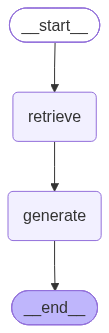

In [12]:
from IPython.display import Image

Image(rag_app.get_graph().draw_mermaid_png())

In [16]:
# Redefine generate to ensure it uses the correct 'gemini' instance
def generate(state: RAGState):
    prompt = f"Handbook:\n{state['context']}\n\nQuestion: {state['question']}"
    response = gemini.models.generate_content(
        model="gemini-3.8-flash",
        contents=prompt,
        config=types.GenerateContentConfig(
            system_instruction="You are SkyFit Gym's assistant. Answer only from the handbook, in 2 lines max. If it's not there, say you don't know.",
        ),
    )
    return {"answer": response.text}

# Recompile the graph to bind the updated node function
graph = StateGraph(RAGState)
graph.add_node("retrieve", retrieve)
graph.add_node("generate", generate)
graph.add_edge(START, "retrieve")
graph.add_edge("retrieve", "generate")
graph.add_edge("generate", END)
rag_app = graph.compile()

# Execute the RAG pipeline
result = rag_app.invoke({"question": "I'm on the quarterly plan and travelling for 2 weeks. Can I pause my membership?"})
print(result["answer"])

Yes, you can freeze your Quarterly membership for 14 days for free, as it allows up to 15 days total (minimum 7 days). 
Please make sure to submit your request at least 2 days in advance via email or the SkyFit app.


In [18]:
# To delete and clear your local Chroma database collection:
if 'vector_db' in globals():
    try:
        vector_db.delete_collection()
        print("🗑️ Chroma collection 'skyfit' has been successfully deleted!")
    except Exception as e:
        print("Collection might already be deleted:", e)
else:
    print("No active vector database found in memory to delete.")

🗑️ Chroma collection 'skyfit' has been successfully deleted!


In [ ]:
from langchain_chroma import Chroma

# 1. Connect to the Chroma database
# LangChain wraps Chroma to let us easily load the collection by its name.
# We must pass the same embedding model ('embedder') so query texts can be converted into the same coordinate space.
vector_db = Chroma(
    collection_name="skyfit",
    embedding_function=embedder
)

# 2. Access the underlying raw collection using LangChain's internal reference
try:
    # Under the hood, LangChain maintains a ._collection reference to the native Chroma DB client
    raw_collection = vector_db._collection
    data = raw_collection.get()
    num_docs = len(data['ids'])

    print(f"✅ Successfully connected to Chroma database collection via LangChain!")
    print(f"Total document chunks indexed: {num_docs}")

    if num_docs > 0:
        print("\n--- Sample Chunk Preview ---")
        print("Chunk ID:", data['ids'][0])
        print("Content snippet:", data['documents'][0][:200] + "...")
except Exception as e:
    print("❌ Could not access collection. (You may need to re-run the cell where 'vector_db.add_documents(chunks)' is called):", e)

In [ ]:
# 3. Query the collection using similarity search
# LangChain automatically handles embedding your question using the defined embedder,
# searches the Chroma vector space, and returns the top 'k' most relevant Document objects.
query = "Are standard plans refundable?"
retrieved_docs = vector_db.similarity_search(query, k=2)

print(f"🔍 Searching the Chroma collection via LangChain for: '{query}'\n")
for i, doc in enumerate(retrieved_docs, start=1):
    print(f"[Match #{i}] Content snippet:")
    print(doc.page_content[:300] + "...")
    print("-" * 50)

Same result as File Search, but now **we** control every step: how to chunk, which embedding model, which database, how many chunks to send, and what the prompt says.

**Try it:** change `k=3` to `k=1`, or switch to the fixed-size chunks, and see how the answers change.

#### Going further

- **Reranking:** vector search is fast but rough. A **reranker** re-reads the top results together with the question and puts the best one first. It's a common extra step between retrieve and generate.
- **Agentic RAG:** here we *always* search, once. In **Part 2**, we turn the handbook into a **tool**, and the agent decides **when** to search, **what** to search for, and **how many times**.

## Recap

| Block | What it does | Key code |
|---|---|---|
| LLM API | Send a prompt, get a response | `client.models.generate_content` |
| System Prompt | Set the AI's role once, used for every message | `system_instruction=` |
| Tool Calling | The LLM asks, your code runs the tool | `tools=[get_stock_prices]` |
| Structured Outputs | Answers in an exact shape your code can use | `response_schema=StockMove` |
| MCP | Plug in an app's ready-made tools | `tools=[deepwiki.session]` |
| RAG | Answer from your documents | File Search, or LangGraph step by step |

**Next, Part 2:** Agent Patterns and Harness Engineering. We combine these blocks into agents that plan, route, check their own work and ask a human before risky actions.